In [1]:
import numpy as np
import time
import torch
import matplotlib.pyplot as plt
plt.rc('text', usetex=False)
import multiprocessing as mp
from typing import Union


from abc import ABC
from epde.preprocessing.cheb import process_point_cheb

from epde.preprocessing.deriv_calculators import Heatmap, AbstractDeriv, AdaptiveFiniteDeriv, PolynomialDeriv, SpectralDeriv, TotalVariation


In [5]:
def masked_mse(arr1, arr2, inner_start=5, inner_end=27):
    """
    Вычисляет MSE между двумя массивами, игнорируя внутреннюю часть [inner_start:inner_end, inner_start:inner_end].
    
    Параметры:
    ----------
    arr1, arr2 : numpy.ndarray
        Двумерные массивы одинакового размера.
    inner_start, inner_end : int
        Границы внутренней области, которую нужно исключить из расчёта.
        
    Возвращает:
    -----------
    mse : float
        Среднеквадратичная ошибка (без учета внутренней части).
    """
    # Создаём маску: True там, где элементы ДОЛЖНЫ учитываться в MSE (вне внутренней части)
    mask = np.ones_like(arr1, dtype=bool)
    mask[inner_start:inner_end, inner_start:inner_end] = False
    
    # Применяем маску к обоим массивам
    masked_arr1 = arr1[mask]
    masked_arr2 = arr2[mask]
    
    # Вычисляем MSE только по валидным элементам
    squared_errors = (masked_arr1 - masked_arr2) ** 2
    mse = np.mean(squared_errors)
    
    return mse

Mean Squared Error (MSE) for noise level 0:
  u_xxx: 0.0029695118154583686
  u_x: 3.5397028934920425e-05
  u_t: 0.00023306118820923342
Mean Squared Error (MSE) for noise level 0.005:
  u_xxx: 0.007635327128005543
  u_x: 6.489816495634505e-05
  u_t: 0.004690367059417571
Mean Squared Error (MSE) for noise level 0.01:
  u_xxx: 0.03148897221984732
  u_x: 0.00018328763641551208
  u_t: 0.032582434429783404


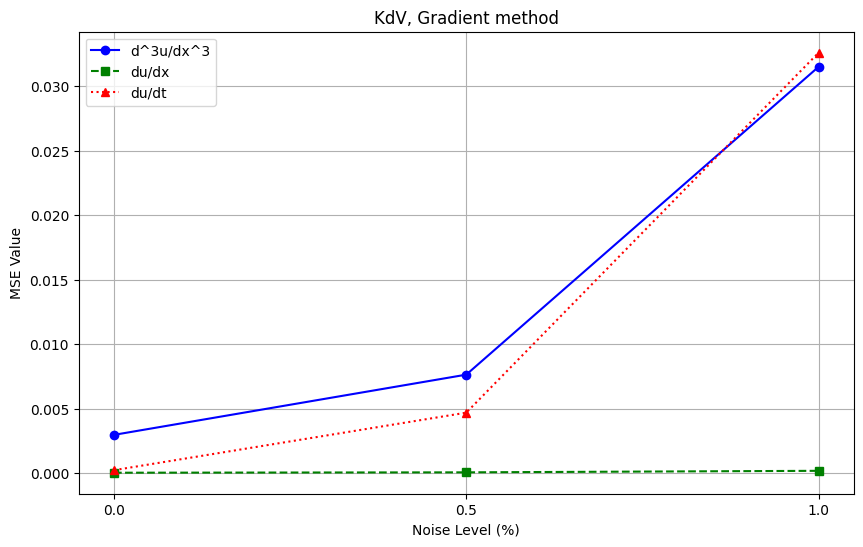

In [ ]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xxx = []
mse_values_u_x = []
mse_values_u_t = []

for noise in noise_levels:
    u_xxx = np.load(f'data_kdv_noise{noise}_u_xxx.npy')
    u_x = np.load(f'data_kdv_noise{noise}_u_x.npy')
    u_t = np.load(f'data_kdv_noise{noise}_u_t.npy')
    
    gradient_xxx = np.load(f'kdv_Gradient_xxx_noise{noise}.npy')
    gradient_x = np.load(f'kdv_Gradient_x_noise{noise}.npy')
    gradient_t = np.load(f'kdv_Gradient_t_noise{noise}.npy')
     
     
    # Вычисление MSE для каждого случая
    mse_u_xxx = masked_mse(u_xxx, gradient_xxx, inner_start=5, inner_end=27)
    mse_u_x = masked_mse(u_x, gradient_x, inner_start=5, inner_end=27)
    mse_u_t = masked_mse(u_t, gradient_t, inner_start=5, inner_end=27)
    
    mse_values_u_xxx.append(mse_u_xxx)
    mse_values_u_x.append(mse_u_x)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xxx: {mse_u_xxx}')
    print(f'  u_x: {mse_u_x}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xxx, marker='o', linestyle='-', color='b', label='d^3u/dx^3')
plt.plot(noise_levels_percent, mse_values_u_x, marker='s', linestyle='--', color='g', label='du/dx')
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label='du/dt')

plt.title('KdV, Gradient method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('kdv_Gradient_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xxx: 0.005828426285846537
  u_x: 4.726093826064356e-05
  u_t: 5.478648229326361e-05
Mean Squared Error (MSE) for noise level 0.005:
  u_xxx: 0.008764411285275156
  u_x: 7.01768548107381e-05
  u_t: 0.0025610989944621757
Mean Squared Error (MSE) for noise level 0.01:
  u_xxx: 0.024793590679052846
  u_x: 0.00018810152937850794
  u_t: 0.01341111697950625


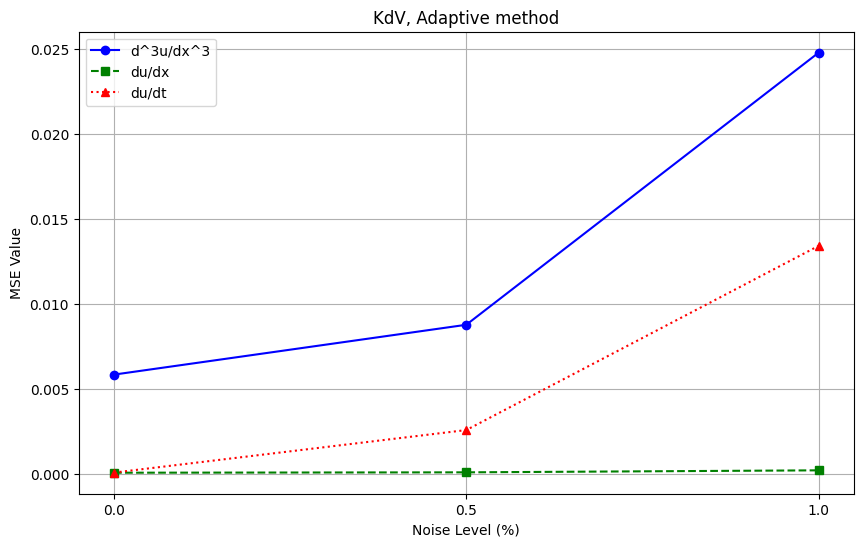

In [ ]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xxx = []
mse_values_u_x = []
mse_values_u_t = []

for noise in noise_levels:
    u_xxx = np.load(f'data_kdv_noise{noise}_u_xxx.npy')
    u_x = np.load(f'data_kdv_noise{noise}_u_x.npy')
    u_t = np.load(f'data_kdv_noise{noise}_u_t.npy')
    
    gradient_xxx = np.load(f'kdv_Adaptive_xxx_noise{noise}.npy')
    gradient_x = np.load(f'kdv_Adaptive_x_noise{noise}.npy')
    gradient_t = np.load(f'kdv_Adaptive_t_noise{noise}.npy')
       
        
    # Вычисление MSE для каждого случая
    mse_u_xxx = masked_mse(u_xxx, gradient_xxx, inner_start=5, inner_end=27)
    mse_u_x = masked_mse(u_x, gradient_x, inner_start=5, inner_end=27)
    mse_u_t = masked_mse(u_t, gradient_t, inner_start=5, inner_end=27)
    
    mse_values_u_xxx.append(mse_u_xxx)
    mse_values_u_x.append(mse_u_x)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xxx: {mse_u_xxx}')
    print(f'  u_x: {mse_u_x}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xxx, marker='o', linestyle='-', color='b', label='d^3u/dx^3')
plt.plot(noise_levels_percent, mse_values_u_x, marker='s', linestyle='--', color='g', label='du/dx')
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label='du/dt')

plt.title('KdV, Adaptive method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('kdv_Adaptive_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xxx: 0.016822046500453013
  u_x: 0.00031413467444742834
  u_t: 0.0001387801711159766
Mean Squared Error (MSE) for noise level 0.005:
  u_xxx: 0.061979198589375895
  u_x: 0.00030964898587721573
  u_t: 0.0031458876827255215
Mean Squared Error (MSE) for noise level 0.01:
  u_xxx: 0.166208656251413
  u_x: 0.000339106841214596
  u_t: 0.016996081640295594


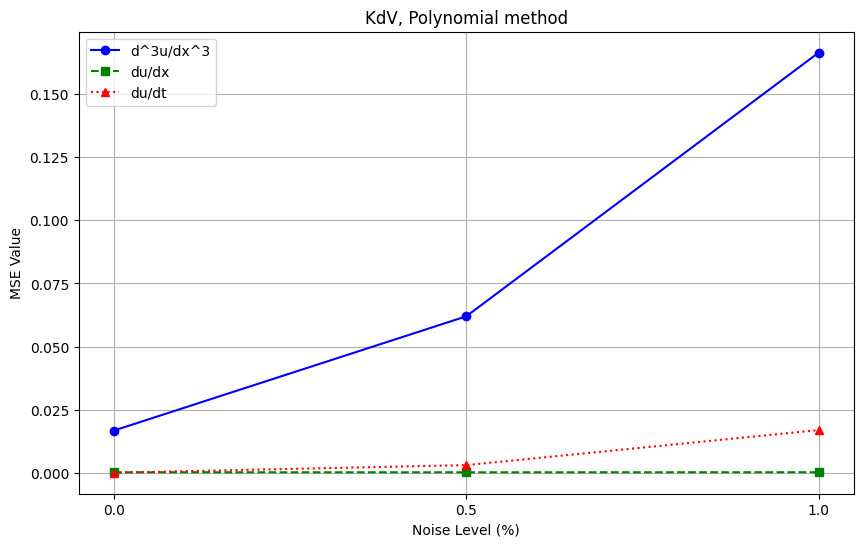

In [11]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xxx = []
mse_values_u_x = []
mse_values_u_t = []

for noise in noise_levels:
    u_xxx = np.load(f'data_kdv_noise{noise}_u_xxx.npy')
    u_x = np.load(f'data_kdv_noise{noise}_u_x.npy')
    u_t = np.load(f'data_kdv_noise{noise}_u_t.npy')
    
    gradient_xxx = np.load(f'kdv_Polynomial_xxx_noise{noise}.npy')
    gradient_x = np.load(f'kdv_Polynomial_x_noise{noise}.npy')
    gradient_t = np.load(f'kdv_Polynomial_t_noise{noise}.npy')

        
    # Вычисление MSE для каждого случая
    mse_u_xxx = masked_mse(u_xxx, gradient_xxx, inner_start=5, inner_end=27)
    mse_u_x = masked_mse(u_x, gradient_x, inner_start=5, inner_end=27)
    mse_u_t = masked_mse(u_t, gradient_t, inner_start=5, inner_end=27)
    
    mse_values_u_xxx.append(mse_u_xxx)
    mse_values_u_x.append(mse_u_x)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xxx: {mse_u_xxx}')
    print(f'  u_x: {mse_u_x}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xxx, marker='o', linestyle='-', color='b', label='d^3u/dx^3')
plt.plot(noise_levels_percent, mse_values_u_x, marker='s', linestyle='--', color='g', label='du/dx')
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label='du/dt')

plt.title('KdV, Polynomial method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('kdv_Polynomial_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xxx: 14.271359706706473
  u_x: 0.010496571867659787
  u_t: 1.3949756451484383
Mean Squared Error (MSE) for noise level 0.005:
  u_xxx: 14.28234982402171
  u_x: 0.010498459422854075
  u_t: 1.3960995424415554
Mean Squared Error (MSE) for noise level 0.01:
  u_xxx: 14.296460090510516
  u_x: 0.010544668429217053
  u_t: 1.396908796893571


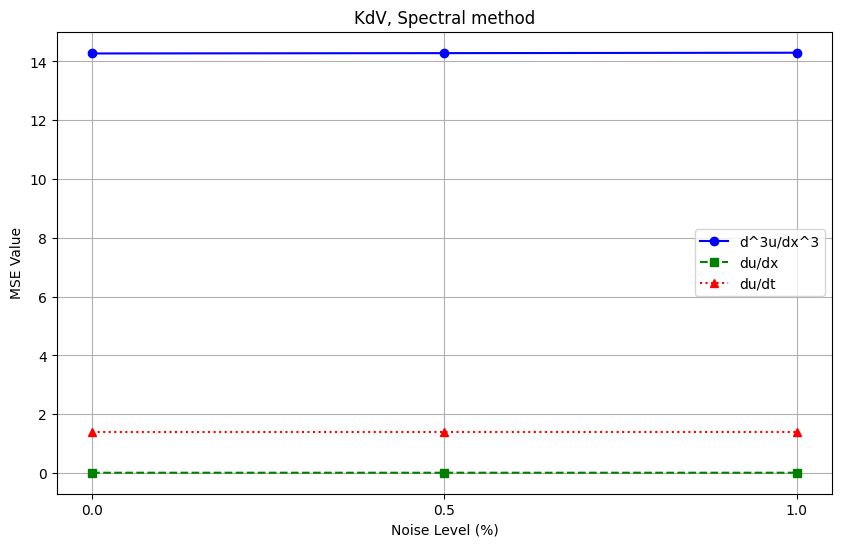

In [ ]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xxx = []
mse_values_u_x = []
mse_values_u_t = []

for noise in noise_levels:
    u_xxx = np.load(f'data_kdv_noise{noise}_u_xxx.npy')
    u_x = np.load(f'data_kdv_noise{noise}_u_x.npy')
    u_t = np.load(f'data_kdv_noise{noise}_u_t.npy')
    
    gradient_xxx = np.load(f'kdv_Spectral_xxx_noise{noise}.npy')
    gradient_x = np.load(f'kdv_Spectral_x_noise{noise}.npy')
    gradient_t = np.load(f'kdv_Spectral_t_noise{noise}.npy')
      
    # Вычисление MSE для каждого случая
    mse_u_xxx = masked_mse(u_xxx, gradient_xxx, inner_start=5, inner_end=27)
    mse_u_x = masked_mse(u_x, gradient_x, inner_start=5, inner_end=27)
    mse_u_t = masked_mse(u_t, gradient_t, inner_start=5, inner_end=27)
    
    mse_values_u_xxx.append(mse_u_xxx)
    mse_values_u_x.append(mse_u_x)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xxx: {mse_u_xxx}')
    print(f'  u_x: {mse_u_x}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xxx, marker='o', linestyle='-', color='b', label='d^3u/dx^3')
plt.plot(noise_levels_percent, mse_values_u_x, marker='s', linestyle='--', color='g', label='du/dx')
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label='du/dt')

plt.title('KdV, Spectral method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('kdv_Spectral_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xxx: 0.19483074779652565
  u_x: 0.03245010806564137
  u_t: 0.21275831590356797
Mean Squared Error (MSE) for noise level 0.005:
  u_xxx: 0.19512723463729642
  u_x: 0.03244075324275761
  u_t: 0.2144753246110437
Mean Squared Error (MSE) for noise level 0.01:
  u_xxx: 0.23464053619323458
  u_x: 0.032525203378894946
  u_t: 0.21312107505262518


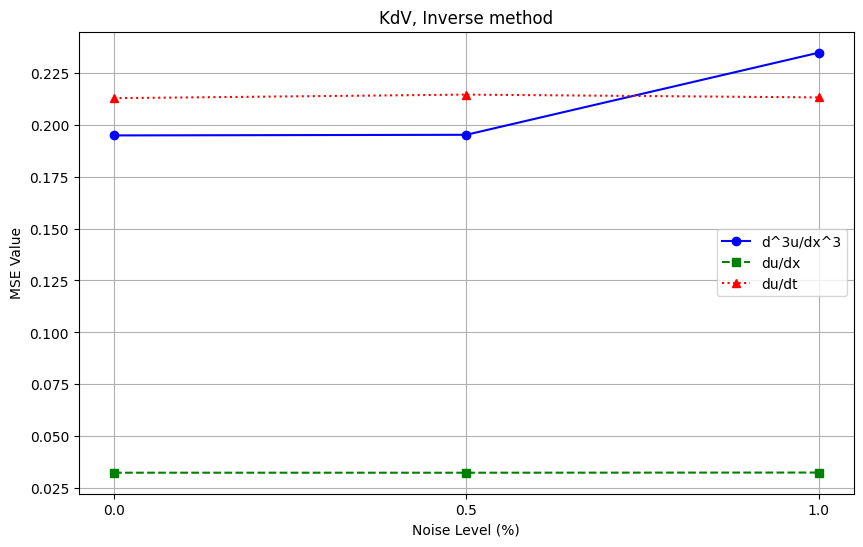

In [13]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xxx = []
mse_values_u_x = []
mse_values_u_t = []

for noise in noise_levels:
    u_xxx = np.load(f'data_kdv_noise{noise}_u_xxx.npy')
    u_x = np.load(f'data_kdv_noise{noise}_u_x.npy')
    u_t = np.load(f'data_kdv_noise{noise}_u_t.npy')
    
    gradient_xxx = np.load(f'kdv_Inverse_xxx_noise{noise}.npy')
    gradient_x = np.load(f'kdv_Inverse_x_noise{noise}.npy')
    gradient_t = np.load(f'kdv_Inverse_t_noise{noise}.npy')
       
    # Вычисление MSE для каждого случая
    mse_u_xxx = masked_mse(u_xxx, gradient_xxx, inner_start=5, inner_end=27)
    mse_u_x = masked_mse(u_x, gradient_x, inner_start=5, inner_end=27)
    mse_u_t = masked_mse(u_t, gradient_t, inner_start=5, inner_end=27)
    
    mse_values_u_xxx.append(mse_u_xxx)
    mse_values_u_x.append(mse_u_x)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xxx: {mse_u_xxx}')
    print(f'  u_x: {mse_u_x}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xxx, marker='o', linestyle='-', color='b', label='d^3u/dx^3')
plt.plot(noise_levels_percent, mse_values_u_x, marker='s', linestyle='--', color='g', label='du/dx')
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label='du/dt')

plt.title('KdV, Inverse method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('kdv_Inverse_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xxx: 0.20022809144024215
  u_x: 0.06874194759149013
  u_t: 0.24164245460289493
Mean Squared Error (MSE) for noise level 0.005:
  u_xxx: 0.20007387059568718
  u_x: 0.06878388206393933
  u_t: 0.24180189657718068
Mean Squared Error (MSE) for noise level 0.01:
  u_xxx: 0.2002081097898837
  u_x: 0.06871469649181174
  u_t: 0.24191767496420302


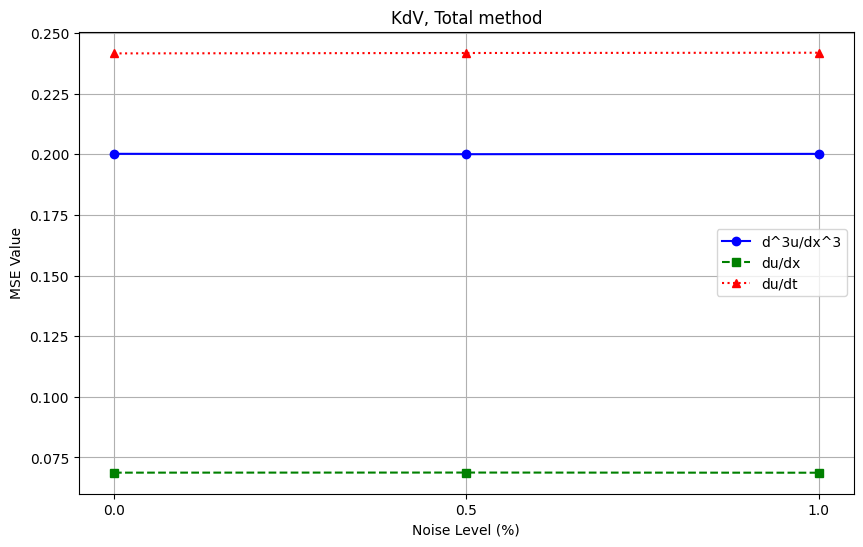

In [14]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xxx = []
mse_values_u_x = []
mse_values_u_t = []

for noise in noise_levels:
    u_xxx = np.load(f'data_kdv_noise{noise}_u_xxx.npy')
    u_x = np.load(f'data_kdv_noise{noise}_u_x.npy')
    u_t = np.load(f'data_kdv_noise{noise}_u_t.npy')
    
    gradient_xxx = np.load(f'kdv_Total_xxx_noise{noise}.npy')
    gradient_x = np.load(f'kdv_Total_x_noise{noise}.npy')
    gradient_t = np.load(f'kdv_Total_t_noise{noise}.npy')
    
    # Вычисление MSE для каждого случая
    mse_u_xxx = masked_mse(u_xxx, gradient_xxx, inner_start=5, inner_end=27)
    mse_u_x = masked_mse(u_x, gradient_x, inner_start=5, inner_end=27)
    mse_u_t = masked_mse(u_t, gradient_t, inner_start=5, inner_end=27)

        
    mse_values_u_xxx.append(mse_u_xxx)
    mse_values_u_x.append(mse_u_x)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xxx: {mse_u_xxx}')
    print(f'  u_x: {mse_u_x}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xxx, marker='o', linestyle='-', color='b', label='d^3u/dx^3')
plt.plot(noise_levels_percent, mse_values_u_x, marker='s', linestyle='--', color='g', label='du/dx')
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label='du/dt')

plt.title('KdV, Total method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('kdv_Total_error.pdf', format='pdf')
plt.show()
